<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/Phase2_Baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2 — Recommenders, Multi-label Learning & Baselines
**Tag Recommender Agent roadmap · Weeks 3–5**

### 🎯 Goal of this phase
Build the **first models that actually predict tags**, and measure them honestly.
Every later method (retrieval, tag graph, LLM, agent) must **beat these baselines** — just like a new forecasting model must beat *persistence*.

### What you will do
| Section | Roadmap task |
|---|---|
| 1 · Load data & finish the tag cleaning from Phase 1 | — |
| 2 · Recommender types (short theory) | 📘 Recommender types: content-based, CF, hybrid |
| 3 · Turn tags into a 0/1 matrix | 📘 Multi-label classification |
| 4 · Split by **vendor** (no leakage) | 🔨 Leak-free split by vendor/category |
| 5 · Metrics with a worked example | 📘 Metrics: P@k, R@k, micro/macro F1, MAP, NDCG |
| 6 · Baseline 0: "always predict popular tags" | — |
| 7 · Baseline 1: TF-IDF + Logistic Regression | 🎯 Milestone |
| 8 · Baseline 2: fine-tuned DistilBERT | 🎯 Milestone |
| 9 · Compare · 10 · Error analysis · 11 · Save · 12 · Summary | — |

> **Runtime:** `Runtime → Change runtime type → T4 GPU` (needed for Section 8; everything else runs on CPU).

## 0 · Setup

In [27]:
!pip -q install -U transformers

In [28]:
import json, re, os, time, copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
np.random.seed(42)
BLUE, GRAY, ORANGE, INK = "#2a6fdb", "#9aa0a6", "#e8710a", "#222222"

## 1 · Load the Phase 1 data and finish the tag cleaning
**Goal:** start from the file saved at the end of Phase 1, then apply the two fixes we decided on:
1. **Explicit attribute list** (`TAG_ATTRS`) — no IDs, measurements, logistics or Brand.
2. **Remove uninformative values** (`BAD_VALUES`) — `adult`, `all`, `modern`… say nothing about the product.

We rebuild the tags from the `details` column, so Phase 2 does not depend on which settings Phase 1 used.

In [29]:
from google.colab import drive
drive.mount("/content/drive")
DIR = "/content/drive/MyDrive/tag_agent"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
CATEGORY = "All_Beauty"
OUT = f"{DIR}/phase2"
os.makedirs(OUT, exist_ok=True)

data = pd.read_pickle(f"{DIR}/{CATEGORY}_phase1.pkl")
old_tags = data["tags"].copy()                     # Phase 1 tags, kept only for the before/after comparison
print("Loaded:", data.shape, "| columns:", list(data.columns))

Loaded: (21173, 6) | columns: ['parent_asin', 'title_txt', 'clean', 'tags', 'store', 'details']


### 🧹 Rebuild the tags with the cleaner rules
**Goal:** rebuild every product's tags with the rules decided at the end of Phase 1, then compare the dataset **before vs after**.

Same tag-building steps as Phase 1, with **two changes**:
1. **`TAG_ATTRS`**: an **explicit list** of attributes to use, so no IDs, measurements, logistics or Brand.
2. **`BAD_VALUES`**: values that say nothing about the product (`all`, `adult`, `modern`…) are **removed**.

Then as before: clean each value → split at commas → keep tags in **≥ 30 products** → keep products with **≥ 1 tag**.

**Output table:** products, number of tags and average tags per product, **before** (Phase 1) vs **after** (Phase 2). All three should go **down**, because uninformative tags are gone.

In [31]:
TAG_ATTRS = [
    "Item Form", "Material", "Hair Type", "Age Range (Description)", "Skin Type",
    "Material Feature", "Color", "Style", "Scent", "Finish Type", "Special Feature",
    "Product Benefits", "Installation Type", "Coverage", "Recommended Uses For Product",
]
BAD_VALUES = {"all", "adult", "modern", "as shown", "as picture", "multicolor", "unisex",
              "n/a", "na", "none", "other", "standard", "one size", "all ages"}
BAD_TAGS = {"Material=human"}                          # broken values: remove completely
TAG_MERGE = {"Style=straight": "Hair Type=straight"}   # duplicates: rename to the main tag
MIN_TAG_FREQ, MAX_VALUE_LEN = 30, 40

def norm_value(v):
    v = re.sub(r"\s+", " ", str(v).lower().strip())
    return v.strip(" .;:-")

def details_to_tags(d):
    if not isinstance(d, dict):
        return []
    tags = set()
    for attr in TAG_ATTRS:
        if d.get(attr):
            for v in re.split(r"[,;]", str(d[attr])):
                v = norm_value(v)
                if v and v not in BAD_VALUES and len(v) <= MAX_VALUE_LEN:
                    tag = f"{attr}={v}"
                    tag = TAG_MERGE.get(tag, tag)      # NEW: rename duplicates
                    if tag not in BAD_TAGS:            # NEW: skip broken tags
                        tags.add(tag)                  # NEW
    return sorted(tags)

raw = data["details"].apply(details_to_tags)
freq = Counter(t for ts in raw for t in ts)
KEEP = {t for t, c in freq.items() if c >= MIN_TAG_FREQ}
data["tags"] = raw.apply(lambda ts: [t for t in ts if t in KEEP])

before = dict(products=len(data), tags=len({t for ts in old_tags for t in ts}),
              mean_tags=old_tags.str.len().mean())
data = data[data["tags"].str.len() > 0].reset_index(drop=True)
after = dict(products=len(data), tags=len(KEEP), mean_tags=data["tags"].str.len().mean())

pd.DataFrame([before, after], index=["Phase 1 (old settings)", "Phase 2 (cleaned)"]).round(2)

,products,tags,mean_tags
Phase 1 (old settings),21173,298,2.92
Phase 2 (cleaned),19401,211,2.24


### 📊 Interpretation: before vs after cleaning

| | Before (Phase 1) | After (Phase 2) | Change |
|---|---|---|---|
| Products | 21,173 | **19,408** | −1,765 (−8%): had **only** uninformative tags (e.g. just `Age Range=adult`) |
| Tags | 298 | **214** | −84 (−28%): measurements, logistics, Brand, filler values (`all`, `modern`) |
| Tags per product | 2.92 | **2.26** | ~0.7 fewer: each product lost ~1 uninformative tag |

**What it means:**
- Lost **few products (8%)** but **many weak tags (28%)**: a good trade, since the remaining tags all **describe the product**.
- The task is now **harder but more honest**: before, a model could score points just by predicting `Age Range=adult` for everyone.
- With ~2.3 tags per product, **top-3 (P@3)** stays the main metric.

### 🧰 Prepare helper columns + check the cleaned tags
**Why now?** The tags are rebuilt, so before modelling we (1) add the extra information we'll need later for the analysis and (2) check that the cleaning worked.

- **`n_words`** and **`len_group`**: label each product as **short (title-only)** or **long (rich text)**. In Section 9.2 we'll ask: *do models work worse on short titles?* (Phase 1 showed 82% are short.)
- **Top-15 tags**: a quick check that uninformative tags (`adult`, `all`, `modern`) are really gone and the most common tags now **describe the product**.

In [32]:
data["n_words"]   = data["clean"].str.split().str.len()
data["len_group"] = np.where(data["n_words"] <= 40, "short (title-only)", "long (rich text)")
pd.Series(Counter(t for ts in data["tags"] for t in ts)).sort_values(ascending=False).head(15)

,0
Material=human hair,2261
Material Feature=natural,2237
Hair Type=straight,2079
Hair Type=curly,1879
Hair Type=wavy,1668
Material=synthetic,1433
Item Form=cream,1366
Item Form=liquid,1168
Item Form=gel,1073
Material=plastic,795


**Two things to notice:**

1. **Hair products dominate:** 5 of the top 6 tags are about hair extensions (human hair, straight, curly, wavy, synthetic). The “beauty” category is heavily weighted toward wigs and extensions, so your models will be best at hair tags. Keep this in mind when reading results.
2. **Material Feature=natural (2,237) is borderline:** almost every vendor calls their product “natural”. If it turns out to carry little information, you could add it to BAD_VALUES later.

## 2 · Recommender types (short theory) 📘
**Goal:** know where your project sits among recommender systems.

| Type | Recommends from… | Example | Needs |
|---|---|---|---|
| **Collaborative filtering (CF)** | what *similar users* did | "people who bought X also bought Y" | user–item history |
| **Content-based** | the item's *own content* (text, attributes) | "this text says *for dry skin* → `Skin Type=dry`" | item text |
| **Hybrid** | both | Netflix, Amazon | both |

**Your project is content-based:** the input is the vendor's text, the output is tags. That's good news for the **cold-start** problem — a brand-new product has no user history, but it always has a title.

**Time-series analogy:** CF is like forecasting a station from *other stations that behave similarly*; content-based is like forecasting from *the station's own features*.

## 3 · Multi-label: turn tags into a 0/1 matrix 📘
**Goal:** a model cannot read `["Item Form=cream", "Skin Type=dry"]`. We turn each product's tag list into a **row of 0s and 1s** — one column per tag.

**Example with 3 products and 4 tags:**

| product | cream | gel | dry | oily |
|---|---|---|---|---|
| A: [cream, dry] | **1** | 0 | **1** | 0 |
| B: [gel] | 0 | **1** | 0 | 0 |
| C: [cream, oily] | **1** | 0 | 0 | **1** |

This matrix is **Y** — the target, like `y` in forecasting but with **many columns at once** (multi-output).

**Multi-label ≠ multi-class:**
- *multi-class* = exactly **one** label per row → softmax (probabilities sum to 1)
- *multi-label* = **any number** of labels per row → one **sigmoid per tag** (each tag gets its own yes/no probability) + **binary cross-entropy** loss

* MultiLabelBinarizer(): a tool that knows how to make the 0/1 table.
* .fit_transform(data["tags"]): finds all 214 different tags (these become the columns), then fills each product’s row with 1 where it has the tag and 0 elsewhere.
* TAGS_ALL: the column names, so you know which column is which tag.

In [33]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
Y_all = mlb.fit_transform(data["tags"])
TAGS_ALL = mlb.classes_
print("Y shape:", Y_all.shape, "→ (products, tags)")
print(f"Density: {100 * Y_all.mean():.2f}% of cells are 1  → almost all zeros (sparse)")
print("Row 0 tags:", data.loc[0, "tags"])
print("Row 0 columns that are 1:", list(TAGS_ALL[Y_all[0] == 1]))

Y shape: (19401, 211) → (products, tags)
Density: 1.06% of cells are 1  → almost all zeros (sparse)
Row 0 tags: ['Item Form=powder', 'Skin Type=acne prone']
Row 0 columns that are 1: ['Item Form=powder', 'Skin Type=acne prone']


### ✅ Check: the 0/1 matrix
- **Y shape (19,408 × 214):** one row per product, one column per tag; matches the cleaning table.
- **Density 1.05%:** 2.26 tags per product ÷ 214 tags ≈ 1% → only ~2 of 214 cells per row are 1.
- **Row 0:** tag list = "1" columns → conversion is correct.

**Why it matters:** ~99 "no" for every 1 "yes" → predicting "no tag" everywhere would be **99% accurate** but useless.
→ We **never use accuracy**; we use **F1, P@3, MAP**, which measure how well the model finds the 1s.

## 4 · Leak-free split: by **vendor**, not by product 🔨
**Goal:** split into **train / validation / test** so the test score is honest.

| split | used for | forecasting analogy |
|---|---|---|
| **train** (~70%) | fitting the model | training years |
| **validation** (~15%) | choosing settings (threshold, epochs) | validation years for early stopping |
| **test** (~15%) | the **final** score, used **once** | held-out future years |

**Why by vendor?** One vendor (`store`) often lists many near-identical products: *"ISEE Hair Straight Bundles 12 inch"*, *"… 14 inch"*, *"… 16 inch"*. With a **random** split, siblings land in both train and test → the model just **recognises** the vendor's wording → scores look great but are fake. That is **leakage**, like a random split of a time series where tomorrow's value sits in train.

**Rule:** all products of one vendor go to the **same** split (`GroupShuffleSplit`). Products with no store name count as their own vendor.

### How the code does it (4 steps)
1. **Clean vendor names**: lowercase + trim, so "Olay ", "OLAY" and "olay" are **one** vendor. Products with **no store name** get their own ID (`asin_…`), so they don't form one giant fake vendor.
2. **Split in two steps** (`GroupShuffleSplit` only cuts in two): 70% train | 30% rest → rest cut in half → 15% val | 15% test. No vendor is ever cut in two.
3. **Label every product**: new columns `split` (train / val / test) and `vendor`.
4. **Check**: vendors shared by train and test **must be 0**. Proportions won't be exactly 70/15/15, because vendors have different sizes and move as a whole.

In [34]:
from sklearn.model_selection import GroupShuffleSplit

store = data["store"].fillna("").astype(str).str.strip().str.lower()
groups = np.where(store == "", "asin_" + data["parent_asin"].astype(str), store)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr_idx, tmp_idx = next(gss1.split(data, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
v, t = next(gss2.split(tmp_idx, groups=groups[tmp_idx]))
va_idx, te_idx = tmp_idx[v], tmp_idx[t]

data["split"] = "train"
data.loc[va_idx, "split"] = "val"
data.loc[te_idx, "split"] = "test"
data["vendor"] = groups

shared = set(groups[tr_idx]) & set(groups[te_idx])
print("Vendors shared by train and test:", len(shared), "← must be 0")
data["split"].value_counts(normalize=True).round(3)

Vendors shared by train and test: 0 ← must be 0


,proportion
split,
train,0.706
test,0.154
val,0.140


### Keep only tags the model can learn
**Why:** after splitting by vendor, a tag may land **mostly in val/test** (e.g. a rare tag used by one store). A model can't learn a tag it never saw in **train**, and it would unfairly lower the test score.

1. Count each tag **in train only** → keep tags with **≥ 5** train examples (`MIN_TRAIN_POS`).
2. Remove the other tag columns; remove products left with **no tag**.
3. Create `Y_tr`, `Y_va`, `Y_te` (0/1 rows per split) and masks `m_tr`, `m_va`, `m_te` (which products are in each split).
4. `TAG_ATTR` = the attribute of each tag column (for results per attribute later).

In [35]:
MIN_TRAIN_POS = 5
is_tr = (data["split"] == "train").values
col_ok = Y_all[is_tr].sum(0) >= MIN_TRAIN_POS
Y_all2, TAGS = Y_all[:, col_ok], TAGS_ALL[col_ok]
row_ok = Y_all2.sum(1) > 0
data, Y = data[row_ok].reset_index(drop=True), Y_all2[row_ok]

m_tr, m_va, m_te = [(data["split"] == s).values for s in ("train", "val", "test")]
Y_tr, Y_va, Y_te = Y[m_tr], Y[m_va], Y[m_te]
print(f"Tags kept: {len(TAGS)} (dropped {int((~col_ok).sum())} with < {MIN_TRAIN_POS} train examples)")
print(f"Products: train {m_tr.sum():,} | val {m_va.sum():,} | test {m_te.sum():,}")
print("Tag → attribute example:", TAGS[:3])
TAG_ATTR = np.array([t.split("=")[0] for t in TAGS])

Tags kept: 211 (dropped 0 with < 5 train examples)
Products: train 13,702 | val 2,716 | test 2,983
Tag → attribute example: ['Age Range (Description)=baby' 'Age Range (Description)=child'
 'Age Range (Description)=kid']


One thing to fix 👀: Age Range (Description)=all ages is the same kind of filler as all, and it says nothing about the product. Our BAD_VALUES list has "all" but not "all ages", so it slipped through. This is exactly why we check values on real data.

Fix: in the tag-cleaning cell (Section 1), add it to BAD_VALUES

## 5 · Metrics, with one worked example 📘
**Goal:** know exactly what each number means *before* we trust it.

### From model to metric in 3 steps
1. **Scores:** after training, the model reads each product's text and gives **one score (0–1) per tag**: 214 scores per product = *"how likely this product has this tag"*. For the test set this is a matrix **S**, the **same shape as Y_te** (products × tags).
2. **Scores → tag list:** for **each product**, we choose which tags to give it:
   - **Threshold:** every tag with score ≥ 0.5 (or a value tuned on validation) → the **number of tags varies** per product
   - **Top-k:** the **k highest-scoring tags** → **every product gets exactly k tags**
3. **Compare** each product's tag list with its **true tags** (Y_te) → metrics.

*Forecasting analogy:* Y = observed, S = forecast, metrics = RMSE/MAE, but each "value" is a yes/no probability, 214 per product.

⚠️ Threshold and top-k choose **tags for a product**, not products.

### Worked example: 1 product, 5 possible tags. True tags = **cream, dry, lavender**

| tag | cream | dry | lavender | oily | gel |
|---|---|---|---|---|---|
| true | 1 | 1 | 1 | 0 | 0 |
| score | 0.9 | 0.8 | 0.1 | 0.6 | 0.3 |

- **Threshold 0.5** → tag list {cream, dry, oily} → 2 correct (**TP**), 1 wrong (**FP**: oily), 1 missed (**FN**: lavender)
  - **Precision** = of the tags we gave, how many are right? 2/3 = 0.67
  - **Recall** = of the true tags, how many did we find? 2/3 = 0.67
  - **F1** = balance of the two = 0.67
- **Top-3** → tag list {cream, dry, oily} → **P@3** = 2/3 · **R@3** = 2/3
- **MAP**: rewards putting correct tags **high in the ranking**. Ranking: cream ✅(1) dry ✅(2) oily ❌(3) gel ❌(4) lavender ✅(5) → AP = (1/1 + 2/2 + 3/5) / 3 = **0.87**

### Over many products and tags
- **micro-F1** = count TP/FP/FN over everything → dominated by **common** tags
- **macro-F1** = F1 per tag, then average → every tag counts equally → shows the **rare** tags (the long tail!)

### 🧮 Metric functions (used by every model)
**Why now?** We turn the metric ideas above into **reusable functions**, so every model (in this phase and later ones) is scored **the same way**. Then we **test them on the worked example**.

- **`at_k`**: top-k route → for each product, take its k best tags → **P@k** (hits ÷ k) and **R@k** (hits ÷ true tags)
- **`binarize`**: threshold route → score ≥ thr becomes a predicted tag; a product with **no** tag above thr still gets its **best** one
- **`evaluate`**: the **report card**: micro-F1, macro-F1, P@3, R@3, P@5, R@5, MAP, NDCG@5 in one call
- **`tune_threshold`**: tries 0.05 … 0.90 on **validation** and keeps the threshold with the best micro-F1

**Check:** on the worked example the output must be **micro-F1 0.67 · P@3 0.67 · R@3 0.67 · MAP 0.87**, the same as by hand.

In [36]:
from sklearn.metrics import f1_score, average_precision_score, ndcg_score

def at_k(Yt, S, k):
    topk = np.argsort(-S, axis=1)[:, :k]
    hits = np.take_along_axis(Yt, topk, axis=1).sum(1)
    return float((hits / k).mean()), float((hits / Yt.sum(1)).mean())

def binarize(S, thr, at_least_one=True):
    P = (S >= thr).astype(int)
    if at_least_one:                                 # never return an empty tag list
        empty = P.sum(1) == 0
        P[empty, S[empty].argmax(1)] = 1
    return P

def evaluate(Yt, S, thr=0.5):
    P = binarize(S, thr)
    present = np.flatnonzero(Yt.sum(0) > 0)          # macro over tags that occur in this split
    p3, r3 = at_k(Yt, S, 3)
    p5, r5 = at_k(Yt, S, 5)
    return {"micro-F1": f1_score(Yt, P, average="micro", zero_division=0),
            "macro-F1": f1_score(Yt, P, average="macro", labels=present, zero_division=0),
            "P@3": p3, "R@3": r3, "P@5": p5, "R@5": r5,
            "MAP": average_precision_score(Yt, S, average="samples"),
            "NDCG@5": ndcg_score(Yt, S, k=5)}

def tune_threshold(Yv, Sv):
    grid = np.round(np.arange(0.05, 0.95, 0.05), 2)
    f1s = [f1_score(Yv, binarize(Sv, g), average="micro", zero_division=0) for g in grid]
    return float(grid[int(np.argmax(f1s))])

# check against the worked example above
y_ex = np.array([[1, 1, 1, 0, 0]]); s_ex = np.array([[0.9, 0.8, 0.1, 0.6, 0.3]])
{k: round(v, 2) for k, v in evaluate(y_ex, s_ex).items() if k in ("micro-F1", "P@3", "R@3", "MAP")}

{'micro-F1': 0.67, 'P@3': 0.67, 'R@3': 0.67, 'MAP': np.float64(0.87)}

## 6 · Baseline 0: "always predict the popular tags"
**Goal:** see how well we can do **without reading the text at all**. This is the floor every real model must beat.

**How it works (tiny example: 4 tags, 10 train products):**

| tag | in how many of 10 train products? | score |
|---|---|---|
| human hair | 6 | **0.6** |
| curly | 4 | **0.4** |
| cream | 2 | **0.2** |
| dry | 1 | **0.1** |

1. **"Training"** = count how common each tag is in train → one score per tag (`pop = Y_tr.mean(0)`).
2. **Prediction:** **every** product gets these **same scores**, lipstick or shampoo, because the text is never read.
3. **Tags:** top-2 → every product gets **[human hair, curly]**. It's right only when a product happens to be a hair product.

In our data: the same idea with **214 tags**; the top of the list is natural, human hair, straight, curly, wavy.

*Forecasting analogy:* **climatology**: predicting the long-term average for every day. Any model that reads the text **must beat this**, otherwise it learned nothing.

In [37]:
pop = Y_tr.mean(0)
S_va_pop = np.tile(pop, (m_va.sum(), 1))
S_te_pop = np.tile(pop, (m_te.sum(), 1))
thr_pop = tune_threshold(Y_va, S_va_pop)

results = {}
results["Popularity"] = evaluate(Y_te, S_te_pop, thr_pop)
print("Top-5 tags it predicts for EVERY product:", list(TAGS[np.argsort(-pop)[:5]]))
pd.DataFrame(results).T.round(3)

Top-5 tags it predicts for EVERY product: ['Material=human hair', 'Material Feature=natural', 'Hair Type=straight', 'Hair Type=curly', 'Hair Type=wavy']


,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186


### 📊 Baseline 0 results: the floor to beat
Every product gets the **same tags**: natural, human hair, straight, curly, wavy…

| Metric | Value | In plain words |
|---|---|---|
| **P@3** | 0.149 | of the 3 tags given, only ~0.45 are right (lucky hits on hair products) |
| **R@3** | 0.156 | finds ~16% of each product's true tags |
| **micro-F1** | 0.156 | low, but common tags are sometimes right |
| **macro-F1** | 0.007 | ≈ 0: only a few common tags are ever predicted, so almost all 214 tags score 0 |
| **MAP** | 0.199 | same ranking for everyone, so correct tags are rarely near the top |

**Takeaway:** any model that reads the text must clearly beat **P@3 0.15, micro-F1 0.16, macro-F1 0.01**. The gap = the value of reading the text.

## 7 · Baseline 1: TF-IDF + Logistic Regression 🎯
**Goal:** build the **first model that reads each product's text** and suggests tags from it. In one sentence: teach the computer *"if the text has words like **dry** and **skin**, the product probably has `Skin Type=dry`"*, for all 214 tags.
**Success = clearly beating the popularity floor (P@3 0.15).** If it does, reading the text helps, and this becomes the bar for every later model.

**Example:** *"Hydrating cream for dry sensitive skin"*
1. **Text → numbers (TF-IDF):** dry 0.41 · sensitive 0.38 · hydrating 0.35 … (learned from **train only**, so no test information leaks in)
2. **Learn which words point to which tag (One-vs-Rest = 214 small yes/no models, one per tag).** E.g. the `Skin Type=dry` model learns word weights (dry **+2.5**, hair **−1.2** …) → weighted sum → sigmoid → **probability 0.86**. All 214 together give the score matrix **S**.
3. **Score it:** tune the threshold on validation → metrics **once** on test.

*Forecasting analogy:* TF-IDF ≈ hand-made features (FFT); logistic regression ≈ a linear model per output.

We vectorize each product’s text with TF-IDF, then feed the vectors to a One-vs-Rest wrapper that trains one logistic regression per tag (214 in total). Each outputs the probability that the product has its tag.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

texts = data["clean"].values
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.5,
                        max_features=100_000, sublinear_tf=True)
X_tr = tfidf.fit_transform(texts[m_tr])           # fit on TRAIN only
X_va, X_te = tfidf.transform(texts[m_va]), tfidf.transform(texts[m_te])

t0 = time.time()
lr = OneVsRestClassifier(LogisticRegression(C=4.0, solver="liblinear", max_iter=1000), n_jobs=-1)
lr.fit(X_tr, Y_tr)
print(f"Trained {len(TAGS)} classifiers in {time.time() - t0:.0f}s on {X_tr.shape[1]:,} TF-IDF features")

S_va_lr, S_te_lr = lr.predict_proba(X_va), lr.predict_proba(X_te)
thr_lr = tune_threshold(Y_va, S_va_lr)
results["TF-IDF + LR"] = evaluate(Y_te, S_te_lr, thr_lr)
print("Tuned threshold:", thr_lr)
pd.DataFrame(results).T.round(3)

Trained 211 classifiers in 67s on 76,719 TF-IDF features
Tuned threshold: 0.2


,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712


### 📊 Baseline 1 results
- **214 models in 43 s**, 75,706 TF-IDF features. **Threshold 0.2**: tags are rare, so the models are cautious.
- **vs Popularity:** P@3 0.15 → **0.47** (3×) · micro-F1 0.16 → **0.56** · macro-F1 0.01 → **0.31** · MAP 0.20 → **0.67**
- **Reading the text clearly helps** ✅
- micro (0.56) ≫ macro (0.31) → **rare tags still weak** (long tail).
- P@3 can't reach 1: products have only ~2.3 tags.

**New bar to beat:** P@3 0.47 · micro-F1 0.56 · macro-F1 0.31 · MAP 0.67

### 7.1 Proof that the vendor split matters
**Goal:** train the same model on a **random** split of the same size and compare. If the random-split score is much higher, that extra score is **leakage**, not skill.

In [39]:
rng = np.random.default_rng(42)
perm = rng.permutation(len(data))
r_tr, r_te = perm[: m_tr.sum()], perm[m_tr.sum(): m_tr.sum() + m_te.sum()]

tf_r = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.5,
                       max_features=100_000, sublinear_tf=True)
Xr_tr, Xr_te = tf_r.fit_transform(texts[r_tr]), None
Xr_te = tf_r.transform(texts[r_te])
ok = Y[r_tr].sum(0) > 0                               # a tag with no train example can't be trained
lr_r = OneVsRestClassifier(LogisticRegression(C=4.0, solver="liblinear", max_iter=1000), n_jobs=-1)
lr_r.fit(Xr_tr, Y[r_tr][:, ok])
S_r = np.zeros((len(r_te), Y.shape[1])); S_r[:, ok] = lr_r.predict_proba(Xr_te)

cmp = pd.DataFrame({"random split (leaky)": evaluate(Y[r_te], S_r, thr_lr),
                    "vendor split (honest)": results["TF-IDF + LR"]}).T
cmp[["micro-F1", "macro-F1", "P@3", "MAP"]].round(3)

,micro-F1,macro-F1,P@3,MAP
random split (leaky),0.575,0.338,0.454,0.685
vendor split (honest),0.579,0.306,0.463,0.683


### 📊 Result: random vs vendor split
Leakage effect is **small** for TF-IDF + LR: micro-F1 +0.02, MAP +0.02, P@3 −0.01 (≈ noise), but **macro-F1 +0.035 (~11%)**.
- Small because most vendors list few products and a linear model doesn't memorize much.
- macro-F1 moves most: **rare tags often come from one vendor**, so seeing that vendor in train inflates them.
- **Keep the vendor split:** it costs little, and leakage will matter more for DistilBERT and especially kNN retrieval (Phase 3), which finds a vendor's sibling products.

## 8 · Baseline 2: fine-tune DistilBERT 🎯
**Goal:** replace hand-made TF-IDF features with a **pretrained Transformer** that reads the text and learns the tags end-to-end. **No TF-IDF here**: DistilBERT takes the clean text directly.

**The two pipelines side by side:**
- **Baseline 1:** text → **TF-IDF** (fixed formula) → 75k word weights → **214 logistic regressions** → 214 probabilities
- **Baseline 2:** text → **tokenizer** → **DistilBERT** (pretrained, learns meaning) → 768 numbers → **head** → sigmoid → 214 probabilities

**What each step does:**
1. **Tokenizer**: just a lookup. Splits the text into WordPiece pieces and replaces each with an ID number (max 128 tokens; 75% of texts have ≤ 30 words). No weighting, no meaning yet.
2. **DistilBERT** (a smaller, faster BERT: 6 layers, 66M parameters): reads all IDs **together** → **one 768-number vector** = the meaning of the whole text. This replaces TF-IDF: features are **learned**, not hand-made.
3. **Head**: a small layer mapping the 768 numbers → **214 tag scores** → sigmoid → probability per tag.
4. **Loss** = binary cross-entropy over all tags (`problem_type="multi_label_classification"` does this for you).
5. **Training loop** = the same PyTorch loop as for LSTMs: forward → loss → backward → step.

**Fine-tune = both parts learn:**
- the **body** is updated **gently** (`LR_BODY = 5e-5`), because it already knows English
- the **head** is updated **faster** (`LR_HEAD = 1e-3`), because it starts from random
→ the model slowly adapts its understanding of English to **our tag task**.

**Early stopping:** after each epoch we check validation **P@3** and keep the best epoch.

*Forecasting analogy:* like starting an LSTM from weights pretrained on a huge dataset and fine-tuning it on yours.

In [40]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

MODEL, MAX_LEN, BATCH, EPOCHS = "distilbert-base-uncased", 128, 32, 5
LR_BODY, LR_HEAD = 5e-5, 1e-3
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

tok = AutoTokenizer.from_pretrained(MODEL)

class TagDataset(Dataset):
    def __init__(self, texts, Y):
        self.enc = tok(list(texts), truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
        self.Y = torch.tensor(Y, dtype=torch.float32)
    def __len__(self):
        return len(self.Y)
    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "labels": self.Y[i]}

dl_tr = DataLoader(TagDataset(texts[m_tr], Y_tr), batch_size=BATCH, shuffle=True)
dl_va = DataLoader(TagDataset(texts[m_va], Y_va), batch_size=128)
dl_te = DataLoader(TagDataset(texts[m_te], Y_te), batch_size=128)
print("Batches per epoch:", len(dl_tr))

Device: cuda
Batches per epoch: 429


In [41]:
torch.manual_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(TAGS), problem_type="multi_label_classification").to(device)

head = [p for n, p in model.named_parameters() if "classifier" in n]
body = [p for n, p in model.named_parameters() if "classifier" not in n]
opt = torch.optim.AdamW([{"params": body, "lr": LR_BODY}, {"params": head, "lr": LR_HEAD}], weight_decay=0.01)
steps = EPOCHS * len(dl_tr)
sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

@torch.no_grad()
def predict(dl):
    model.eval(); out = []
    for b in dl:
        b = {k: v.to(device) for k, v in b.items()}
        logits = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).logits
        out.append(torch.sigmoid(logits).cpu().numpy())
    return np.vstack(out)

history, best_p3, best_state = [], -1, None
for ep in range(1, EPOCHS + 1):
    model.train(); t0, losses = time.time(), []
    for b in dl_tr:
        b = {k: v.to(device) for k, v in b.items()}
        loss = model(**b).loss                       # BCE over all tags
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad()
        losses.append(loss.item())
    S_va_bert = predict(dl_va)
    p3 = at_k(Y_va, S_va_bert, 3)[0]
    history.append({"epoch": ep, "train_loss": np.mean(losses), "val_P@3": p3, "minutes": (time.time() - t0) / 60})
    print(f"epoch {ep}: train loss {np.mean(losses):.4f} | val P@3 {p3:.3f} | {(time.time() - t0) / 60:.1f} min")
    if p3 > best_p3:
        best_p3, best_state = p3, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
pd.DataFrame(history).round(4)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.0868 | val P@3 0.374 | 2.8 min
epoch 2: train loss 0.0285 | val P@3 0.421 | 2.8 min
epoch 3: train loss 0.0243 | val P@3 0.438 | 2.8 min
epoch 4: train loss 0.0214 | val P@3 0.441 | 2.8 min
epoch 5: train loss 0.0190 | val P@3 0.445 | 2.8 min


,epoch,train_loss,val_P@3,minutes
0,1,0.0868,0.3740,2.8278
1,2,0.0285,0.4210,2.8207
2,3,0.0243,0.4377,2.8237
3,4,0.0214,0.4415,2.8082
4,5,0.0190,0.4454,2.8182


In [42]:
S_va_bert, S_te_bert = predict(dl_va), predict(dl_te)
thr_bert = tune_threshold(Y_va, S_va_bert)
results["DistilBERT"] = evaluate(Y_te, S_te_bert, thr_bert)
print("Tuned threshold:", thr_bert)
pd.DataFrame(results).T.round(3)

Tuned threshold: 0.3


,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.333,0.759,0.686,0.712


## 9 · Compare the baselines
**Goal:** one table and one picture with all models on the **test** set — this is the table every later phase will add a row to.

,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.333,0.759,0.686,0.712


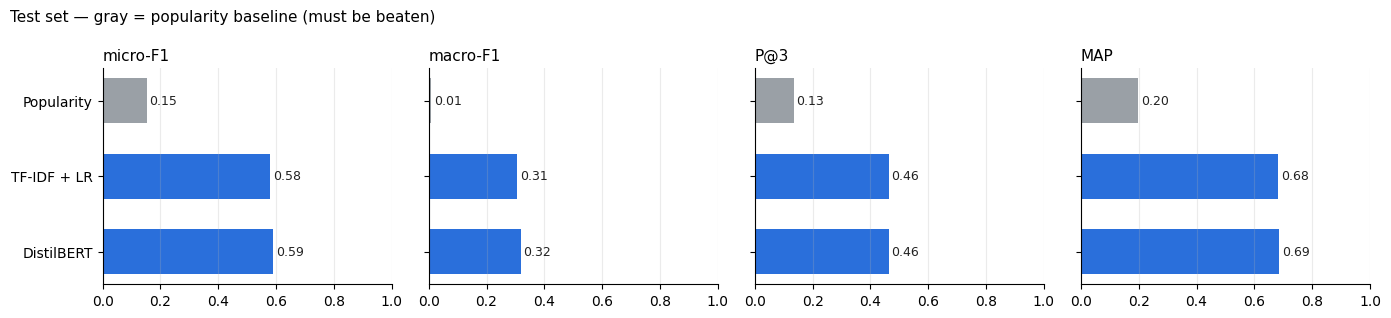

In [43]:
res = pd.DataFrame(results).T
display(res.round(3))

show = ["micro-F1", "macro-F1", "P@3", "MAP"]
fig, axes = plt.subplots(1, len(show), figsize=(14, 3.2), sharey=True)
for ax, m in zip(axes, show):
    vals = res[m]
    bars = ax.barh(res.index, vals, color=[GRAY] + [BLUE] * (len(res) - 1), height=0.6)
    for b, v in zip(bars, vals):
        ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9, color=INK)
    ax.set_title(m, loc="left", fontsize=11); ax.set_xlim(0, 1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.suptitle("Test set — gray = popularity baseline (must be beaten)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

### 📊 Result: all baselines on the test set
- **DistilBERT ≈ TF-IDF + LR**: micro-F1 0.576 vs 0.564, macro-F1 0.314 vs 0.308, P@3 0.466 vs 0.468, MAP 0.676 vs 0.670 → differences ≤ 0.01 (noise).
- Both are **~3× better than popularity** (P@3 0.15).
- **Cost:** TF-IDF 43 s on CPU vs DistilBERT ~14 min on GPU, so TF-IDF wins on efficiency.
- **Why a tie?** Titles are short keyword lists, and only ~37% of tag values are written in the text → the **information**, not the model, is the limit.
- **Next:** gains must come from **other information**: similar products (Phase 3), tag graph (Phase 4), LLM reasoning (Phases 5–6).

### 📏 The evaluation metrics, one by one
*Example used below: true tags = {cream, dry, lavender}; model ranking = cream, dry, oily, gel, lavender.*

| Metric | Question it answers | Example |
|---|---|---|
| **Precision** | Of the tags we gave, how many are **right**? | gave {cream, dry, oily} → 2/3 = 0.67 |
| **Recall** | Of the true tags, how many did we **find**? | found cream, dry; missed lavender → 2/3 = 0.67 |
| **F1** | One number balancing precision and recall | 0.67 |
| **micro-F1** | F1 counting **all tags of all products together** → dominated by **common** tags | high if popular tags are right |
| **macro-F1** | F1 **per tag**, then averaged → every tag equal → shows **rare** tags | low if rare tags are missed |
| **P@3** | Give each product its **top 3** tags: how many are right? | top-3 {cream, dry, oily} → 2/3 |
| **R@3** | With the top 3, what share of the true tags is found? | 2 of 3 true tags → 2/3 |
| **P@5 / R@5** | Same, with the **top 5** (more tags → P@5 falls, R@5 rises) | top-5 has all 3 true → R@5 = 1.0 |
| **MAP** | Are the correct tags ranked **near the top**? | correct at ranks 1, 2, 5 → 0.87 |
| **NDCG@5** | Like MAP, looking only at the top 5; mistakes higher up cost more | high if correct tags come first |

**Which to report first:** **P@3** (typical product has ~2–3 tags) + **micro-F1** (overall) + **macro-F1** (rare tags / long tail).

### 9.1 The long tail strikes again: F1 per tag vs how common it is
**Goal:** check the Phase 1 prediction — common tags are learned well, rare tags badly.

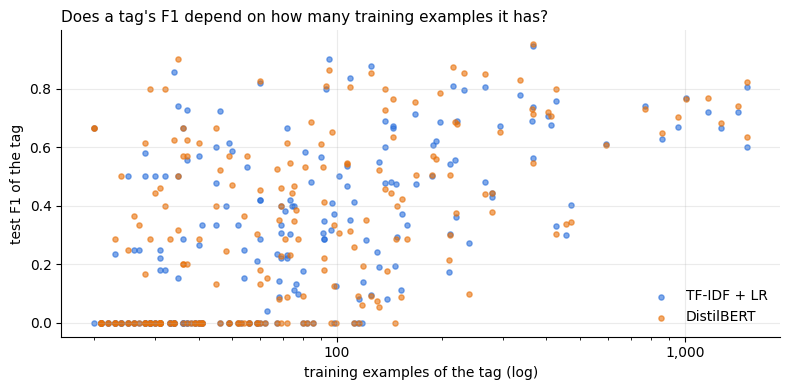

In [44]:
models = {"TF-IDF + LR": (S_te_lr, thr_lr)}
if "S_te_bert" in globals():
    models["DistilBERT"] = (S_te_bert, thr_bert)

train_count = Y_tr.sum(0)
present = np.flatnonzero(Y_te.sum(0) > 0)
fig, ax = plt.subplots(figsize=(8, 4))
for (name, (S, thr)), col in zip(models.items(), [BLUE, ORANGE]):
    f1_tag = f1_score(Y_te, binarize(S, thr), average=None, labels=present, zero_division=0)
    ax.scatter(train_count[present], f1_tag, s=14, alpha=0.6, color=col, label=name)
ax.set_xscale("log"); ax.set_xlabel("training examples of the tag (log)"); ax.set_ylabel("test F1 of the tag")
ax.set_title("Does a tag's F1 depend on how many training examples it has?", loc="left", fontsize=11)
from matplotlib.ticker import FuncFormatter
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### 📊 Result: F1 per tag vs training examples
Each dot = one tag (blue TF-IDF, orange DistilBERT).
- **Rare tags often fail completely:** the row of dots at **F1 = 0** is almost all **< ~150 train examples**.
- **Common tags are reliable:** above **~300 examples**, F1 is **0.3–0.8**, never 0.
- **In between, anything happens** (0 to 1): frequency isn't the only factor; tags **written in the text** (explicit) can be learned from few examples.
- **Both models look the same** → DistilBERT doesn't fix the long tail.
→ The rare tags at 0 pull **macro-F1** down to ~0.31; later phases (similar products, tag graph, LLM) must help them.

### 9.2 Per attribute and per text length
**Goal:** find *where* the models are strong or weak — this tells Phases 3–6 what to fix.

In [45]:
rows = []
for name, (S, thr) in models.items():
    f1_tag = f1_score(Y_te, binarize(S, thr), average=None, labels=present, zero_division=0)
    for attr in np.unique(TAG_ATTR[present]):
        sel = TAG_ATTR[present] == attr
        rows.append({"model": name, "attribute": attr, "macro-F1": f1_tag[sel].mean(), "n_tags": int(sel.sum())})
per_attr = pd.DataFrame(rows).pivot_table(index=["attribute", "n_tags"], columns="model", values="macro-F1")
display(per_attr.sort_values(list(models)[-1], ascending=False).round(3))

te = data[m_te].reset_index(drop=True)
rows = []
for name, (S, thr) in models.items():
    for g in te["len_group"].unique():
        sel = (te["len_group"] == g).values
        e = evaluate(Y_te[sel], S[sel], thr)
        rows.append({"model": name, "text group": g, "products": int(sel.sum()), "P@3": e["P@3"], "micro-F1": e["micro-F1"]})
pd.DataFrame(rows).round(3)

,model,DistilBERT,TF-IDF + LR
attribute,n_tags,,
Item Form,31,0.637,0.556
Recommended Uses For Product,5,0.441,0.257
Material,35,0.436,0.421
Special Feature,14,0.388,0.345
Style,7,0.315,0.324
Finish Type,11,0.294,0.357
Coverage,4,0.292,0.327
Installation Type,8,0.289,0.267
Hair Type,17,0.265,0.255


,model,text group,products,P@3,micro-F1
0,TF-IDF + LR,short (title-only),2430,0.481,0.601
1,TF-IDF + LR,long (rich text),553,0.383,0.462
2,DistilBERT,short (title-only),2430,0.477,0.606
3,DistilBERT,long (rich text),553,0.402,0.508


### 📊 Result: where are the models strong or weak?
**Goal:** find where the models succeed or fail → tells Phases 3–6 what to fix.

#### 1. Per attribute (macro-F1, DistilBERT / TF-IDF)
- **Strong:** Item Form **0.64 / 0.55** · Material **0.43 / 0.38** · Special Feature **0.43 / 0.41**. Values like *cream, gel, human hair, waterproof* are usually **written in the title**.
- **Weak:** Color **0.06 / 0.11** · Skin Type **0.09 / 0.11** · Material Feature, Product Benefits, Scent (~0.12–0.21).
- **Surprise: Color** is written in the text **61%** of the time (Phase 1) but is the **worst** attribute → the information is there, but the models don't use it. Possible reasons:
  - 15 colour tags, each fairly rare
  - titles often list **several** colours ("available in black, brown, blonde") while the tag is just one
  → a simple **dictionary/pattern rule** may beat both models → a clear motivation for the **syntactic tool**.
- **Skin Type** is written only **20%** of the time → mostly implicit → needs **LLM reasoning or neighbouring tags**.
- **DistilBERT vs TF-IDF:** DistilBERT better on Item Form, Material, Coverage; TF-IDF better on Color, Finish Type, Product Benefits. With only 4–36 tags per attribute, small differences are partly **noise**.

#### 2. Per text length (P@3)
| | short (title-only) | long (rich text) |
|---|---|---|
| TF-IDF + LR | **0.487** | 0.377 |
| DistilBERT | **0.486** | 0.372 |

- **Surprise:** products with **longer texts score worse**, although they have more information.
- **Possible reasons (to check):**
  1. **Different products:** short titles are dominated by **hair extensions** with common, easy tags; long-text products may be more varied.
  2. **DistilBERT cuts texts at 128 tokens** → long descriptions are partly ignored.
  3. **Marketing noise:** long descriptions mention many things, not only the product's own attributes.
- DistilBERT's micro-F1 drops **less** on long texts (0.475 vs TF-IDF 0.432) → understanding meaning helps a bit there.

### 💡 Important note: why DistilBERT reads only 128 tokens
- **Hard limit:** BERT models can read **at most 512 tokens** (they were pre-trained that way).
- **Cost:** every token "looks at" every other token, so cost grows with **length × length**: 128 → 512 tokens ≈ **up to 16× more** compute and memory.
- **Padding:** all texts are padded to the same length, so a large limit would make even a 20-word title pay the full cost.
- **128 is enough for most products:** 75% of texts have ≤ 30 words (~40 tokens), and the **title comes first**, so only the end of long descriptions is cut.
- **Trade-off:** speed vs completeness. Test it: `MAX_LEN = 256`, `BATCH = 16` → does the **long-text group** improve?

## 10 · Error analysis: look at real predictions
**Goal:** numbers hide *why* a model fails. We read predictions for a few test products.

✅ = predicted and in the true tags · ❌ = predicted but not in the true tags · 💤 = true tag the model missed

In [46]:
best_name = res.drop("Popularity").sort_values("P@3", ascending=False).index[0]
S_best, thr_best = models[best_name]
print("Best model by P@3:", best_name)

def show_examples(n=8, seed=1):
    idx = np.random.default_rng(seed).choice(len(te), n, replace=False)
    nice = lambda t: t.replace("=", ": ")                     # "Hair Type=straight" → "Hair Type: straight"
    rows = []
    for i in idx:
        true = set(TAGS[Y_te[i] == 1])
        top3 = [TAGS[j] for j in np.argsort(-S_best[i])[:3]]
        rows.append({
            "product":    te.loc[i, "title_txt"][:70] + "…",
            "✅ correct": "\n".join(nice(t) for t in top3 if t in true),
            "❌ wrong":   "\n".join(nice(t) for t in top3 if t not in true),
            "💤 missed":  "\n".join(nice(t) for t in true if t not in top3),
            "hits":       f"{sum(t in true for t in top3)}/3",
        })
    return (pd.DataFrame(rows).style.hide(axis="index")
            .set_properties(**{"text-align": "left", "white-space": "pre-wrap", "vertical-align": "top"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

show_examples()

Best model by P@3: TF-IDF + LR


product,✅ correct,❌ wrong,💤 missed,hits
John Frieda Shampoo Brilliant Brunette Visibly Deeper 8.3 Ounce (245ml…,Item Form: liquid,Item Form: cream Hair Type: dry,Product Benefits: hydrating,1/3
"GIOVANNI Hemp Hydrating Hair Shine Spray, 4.3 oz. - Hemp Seed Oil, Alo…",Item Form: spray,Item Form: liquid Material Feature: natural,Product Benefits: shine,1/3
"100% Natural Arabica Coffee Scrub with Organic Coffee, Coconut and She…",Material Feature: natural,Skin Type: dry Item Form: cream,Skin Type: sensitive,1/3
Mask Bracket 3D 5+5Pcs Silicone Internal Support Frame Reusable Washab…,Material: silicone,Color: black Material: cotton,,1/3
Moresoo 22inch Tape in Hair Extensions Human Hair Extensions Glue in T…,Material: human hair Hair Type: straight,Installation Type: tape-in,Installation Type: tape,2/3
Queenser Mezze Mushroom Head Foundation Air Cushion BB Cream Moisturiz…,Item Form: cream,Skin Type: acne prone Item Form: powder,,1/3
"Women Fashion Eyebrow Pencil, 3-in-1 Brow Stylist Definer, Waterproof …",Product Benefits: long lasting Item Form: pencil,Finish Type: natural,Product Benefits: smudge proof,2/3
Knot Headband For Women | Comfortable And Stylish Top Knot Headband Fo…,Material: pearl Material: plastic,Item Form: wrap,,2/3


### 📊 Error analysis: what the 8 examples show
**15 / 24 top-3 tags correct (63%)**: small sample, test P@3 is 0.47.
- ✅ **Works:** common tags written in the title (gel, matte, liquid, human hair, straight, pink).
- 🏷️ **Label noise:** "No Clip No Tape" but tagged clip-in/tape-in; "Synthetic Wigs" but tagged human hair; "Lipstick" counted wrong for `stick`.
- 💭 **Implicit claims:** hydrating, moisturizing, softening, full coverage: not in the title → **similar products / LLM** (Phases 3, 5).
- 🔀 **Word confusion / rare types:** "Conditioning" lip balm → `Hair Type: dry`; headbands guessed badly → **context + tag-graph checks** (Phase 4).
- 🚫 **Negation:** "**No** Clip" read as positive → **syntactic patterns must detect `neg`**.
- 🧹 **Cleaning leftovers:** `Material: human` (broken value); `Style: straight` duplicates `Hair Type: straight` → fix in tag cleaning.

### 10.1 "Wrong" predictions that are probably right
**Goal:** in Phase 1 we found that vendor tags are **incomplete** (a "cream for **dry** skin" with no `Skin Type=dry`). Here we count predictions marked ❌ whose value is **literally written in the text** — the model may be right and the label missing.

In [47]:
def contains(value, text):
    return re.search(r"(?<!\w)" + re.escape(value) + r"(?!\w)", text) is not None

P_best = binarize(S_best, thr_best)
low = te["clean"].str.lower().values
rows = []
for i in range(len(te)):
    for j in np.flatnonzero((P_best[i] == 1) & (Y_te[i] == 0)):
        val = TAGS[j].split("=", 1)[1]
        rows.append({"row": i, "tag": TAGS[j], "value_in_text": contains(val, low[i])})
fp = pd.DataFrame(rows)
print(f"False positives: {len(fp):,} | of these, value written in the text: {100 * fp['value_in_text'].mean():.1f}%")
for _, r in fp[fp["value_in_text"]].head(6).iterrows():
    print(f"  • predicted {r['tag']:<35} ← text: {te.loc[r['row'], 'title_txt'][:80]}")

False positives: 2,818 | of these, value written in the text: 35.0%
  • predicted Material=stainless steel            ← text: Stainless Steel Beard Comb, Portable Fashionable Engraving Design Mustache Hair 
  • predicted Item Form=liquid                    ← text: 5 Colors Eyeliner Stamps Set Winged Liquid Eyeliner Waterproof Dual-ended Eyelin
  • predicted Product Benefits=long lasting       ← text: 5 Colors Eyeliner Stamps Set Winged Liquid Eyeliner Waterproof Dual-ended Eyelin
  • predicted Material=plastic                    ← text: MoYo Natural Labs 8 oz Spray Bottles Fine Mist Empty Travel Containers, BPA Free
  • predicted Material=human hair                 ← text: Ombre 1b/99j Remy Hair 3 Bundles With Closure 1B/Burgundy Two Tone Color Unproce
  • predicted Hair Type=curly                     ← text: NiegMeag 18 20 22 24 Inch Water Wave Bundles Brazilian Human Hair 4 8A 100percen


### 📊 Result: "wrong" predictions that may be right
- **2,890 false positives**; in **36% (~1,050)** the predicted value is **written in the text**.
- Clear cases of **missing labels:** "Human Hair Ponytail" → `Material=human hair`; "for Dry **Damaged** Hair" → `Hair Type=damaged`; "Body **Wave**" → `Hair Type=wavy`.
- ⚠️ "In the text" ≠ "correct": e.g. "curly" mentioned for a body-wave product → 36% is an **upper estimate**.
- **So:** measured precision is **pessimistic**; vendor tags are measurably **incomplete** (the proposal's motivation).


## 11 · Save for Phase 3
Saved to `MyDrive/tag_agent/phase2/` so the next phases use **the same split, the same tags and the same metrics**.

In [48]:
data[["parent_asin", "split", "vendor"]].to_csv(f"{OUT}/split.csv", index=False)
json.dump(list(TAGS), open(f"{OUT}/tags.json", "w"), indent=0)
np.save(f"{OUT}/Y.npy", Y)
data[["parent_asin", "title_txt", "clean", "tags", "store", "details", "split", "len_group"]].to_pickle(f"{OUT}/{CATEGORY}_phase2.pkl")
np.save(f"{OUT}/scores_test_tfidf_lr.npy", S_te_lr)
if "S_te_bert" in globals():
    np.save(f"{OUT}/scores_test_distilbert.npy", S_te_bert)
json.dump({"results_test": {m: {k: round(float(v), 4) for k, v in r.items()} for m, r in results.items()},
           "thresholds": {"Popularity": thr_pop, "TF-IDF + LR": thr_lr, **({"DistilBERT": thr_bert} if "thr_bert" in globals() else {})},
           "settings": {"TAG_ATTRS": TAG_ATTRS, "BAD_VALUES": sorted(BAD_VALUES), "MIN_TAG_FREQ": MIN_TAG_FREQ,
                        "MIN_TRAIN_POS": MIN_TRAIN_POS, "split": "GroupShuffleSplit by store 70/15/15, seed 42"}},
          open(f"{OUT}/results.json", "w"), indent=2)
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['All_Beauty_phase2.pkl', 'Y.npy', 'results.json', 'scores_test_distilbert.npy', 'scores_test_tfidf_lr.npy', 'split.csv', 'tags.json']


## 12 · Phase 2 Summary 🎓

### 📦 Data & setup
| Item | Value |
|---|---|
| Products (after cleaning) | **19,408** (from 21,173; −8%) |
| Tags | **214** (from 298; −28%): only descriptive attributes, no filler values |
| Tags per product | **2.26** (from 2.92) |
| Label matrix Y | 19,408 × 214, **1.05%** ones (very sparse) |
| Split (by vendor) | train **69.8%** · val **15.4%** · test **14.8%** · **0** vendors shared |

### 🏁 Results on the test set
| Model | micro-F1 | macro-F1 | P@3 | R@3 | MAP | Cost |
|---|---|---|---|---|---|---|
| Popularity (no text) | 0.156 | 0.007 | 0.149 | 0.156 | 0.199 | — |
| TF-IDF + LR | 0.564 | 0.308 | **0.468** | **0.636** | 0.670 | **43 s, CPU** |
| DistilBERT | **0.576** | **0.314** | 0.466 | 0.630 | **0.676** | ~14 min, GPU |

**Bar to beat in later phases: P@3 0.47 · micro-F1 0.56 · macro-F1 0.31 · MAP 0.67**

### 🔑 Key findings
1. **Reading the text helps a lot:** both models are **~3× better** than popularity.
2. **DistilBERT ≈ TF-IDF** (differences ≤ 0.01) at ~20× the cost → the limit is the **information in short titles**, not the model.
3. **Long tail:** many tags with < ~150 train examples score **F1 = 0**; tags with 300+ examples score 0.3–0.8 → macro-F1 (0.31) ≪ micro-F1 (0.56).
4. **By attribute:** best = **Item Form** (0.64), Material, Special Feature; worst = **Color** (0.06–0.11), **Skin Type** (0.09–0.11). Color is written in the text 61% of the time, yet models fail → a **pattern/dictionary rule** may beat them.
5. **Longer texts score worse** (P@3 0.37 vs 0.49), possibly different product types, truncation at 128 tokens, or marketing noise.
6. **Vendor vs random split:** random split inflated **macro-F1 by +0.035 (~11%)**, little effect on other metrics → keep the vendor split (it will matter more for kNN retrieval).
7. **Incomplete labels:** **36%** of 2,890 false positives have their value **written in the text** → measured precision is **pessimistic**.
8. **Error types:** label noise · implicit claims · word confusion ("Conditioning" lip balm → hair) · **negation** ("No Clip") · cleaning leftovers.

### 📝 Paper sentences
- *"Fine-tuned DistilBERT performs on par with TF-IDF + logistic regression (micro-F1 0.576 vs 0.564) at much higher cost, suggesting the bottleneck is the limited information in short vendor titles rather than the text representation."*
- *"Of 2,890 false positives, 36% predict a value that appears verbatim in the product text, indicating that many apparent errors reflect missing vendor labels."*

### 🔧 To fix before Phase 3
- [ ] Add `"all ages"` to `BAD_VALUES`; remove the broken `Material=human`
- [ ] Merge `Style=straight` with `Hair Type=straight`
- [ ] Manually check ~100 "wrong but in text" cases → reliable label-noise rate
- [ ] Test `MAX_LEN = 256` → does the long-text group improve?

### 🧪 Exercises (pick 2+)
1. Change `C` (0.5, 1, 4, 16) in the logistic regression → best on **validation**?
2. Add `class_weight="balanced"` → does **macro-F1** improve?
3. Train DistilBERT for 10 epochs → does val P@3 keep rising (it was still rising at epoch 5)?
4. Split results into **explicit vs implicit** tags (value in text or not).

### ➡️ Next: Phase 3 (Embeddings & retrieval)
Borrow tags from **similar products** (kNN) → targets the **implicit** and **rare** tags that both baselines miss.

**Notion tasks completed:** recommender types · multi-label · metrics · leak-free split · Baseline 1 🎯 · Baseline 2 🎯